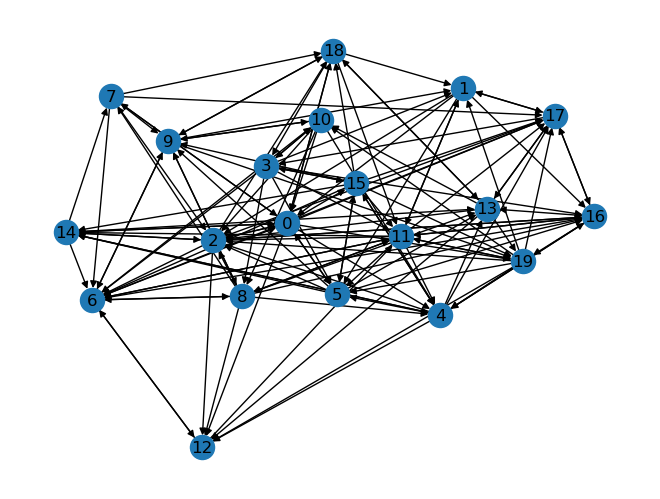

In [3]:
import networkx as nx
import pyomo.environ as pyo
import matplotlib.pyplot as plt
import random, time

def descendants(G, source):
    seen = set()
    stack = [source]
    while stack:
        node = stack.pop()
        for neighbor in G.neighbors(node):
            if neighbor not in seen:
                seen.add(neighbor)
                stack.append(neighbor)
        print('stack', stack)
    seen.discard(source)
    return seen


def reachability_intersection_source_sink(G, pairs):
    """
    Given a DiGraph G, and a list of (start, end) node pairs,
    return the set of nodes that lie on some path from each start to end.
    Done via DFS (see above)

    When considering s --> ... and t --> ..., the intersection of the two
    sets is the entire subgraph. 
    
    Returns: Set of nodes in the intersection
    """
    intersect_sets = []

    for s, t in pairs:
        # Nodes reachable from source
        reachable_from_s = set(nx.descendants(G, s)) | {s}
        # Nodes that can reach sink (reverse graph)
        reachable_to_t = set(nx.descendants(G.reverse(), t)) | {t}
        # Nodes on some path from s -> t
        path_nodes = reachable_from_s & reachable_to_t
        intersect_sets.append(path_nodes)
    
    # Intersection across all source-sink pairs
    return set.intersection(*intersect_sets)

def edges_within_subset(G, nodes):
    """
    Return all edges given a set of nodes
    """
    nodes_set = set(nodes)
    return [(u, v) for u, v in G.edges() if u in nodes_set and v in nodes_set]


def build_residual_graph(G, flow):
    R = nx.DiGraph()
    for (i, j) in G.edges:
        cap = G[i][j]["capacity"]
        f = flow[(i, j)]

        if cap - f > 1e-9:
            # Forward residual 
            R.add_edge(i, j, capacity=cap - f)
        else:
            # Backward residual
            R.add_edge(j, i, capacity=f)
    return R

def get_ST_sets(G:nx.DiGraph, flow: dict, s):
    R = build_residual_graph(G, flow)
    S = set(nx.dfs_preorder_nodes(R, source=s))
    T = set(G.nodes) - S
    return R, S, T

G = nx.gnp_random_graph(20, 0.4, directed=True)
pairs = [(2, 6)]
common_nodes = reachability_intersection_source_sink(G, pairs)
edges = edges_within_subset(G, common_nodes)
subG = G.subgraph(common_nodes)
edges = list(subG.edges())
nx.draw(subG, node_size=300, with_labels=True)
plt.show()

for u, v in G.edges:
    G[u][v]["capacity"] = 1

In [2]:
def max_flow(G: nx.DiGraph, s, t):
    model = pyo.ConcreteModel()
    # Sets, Params, Vars
    model.N = pyo.Set(initialize=list(G.nodes))
    model.A = pyo.Set(initialize=list(G.edges), dimen=2)
    cap = {(i, j): G[i][j].get('capacity') for (i, j) in G.edges}
    model.cap = pyo.Param(model.A,initialize=cap,within=pyo.NonNegativeReals)
    model.x = pyo.Var(
        model.A, domain=pyo.NonNegativeReals,
        initialize=lambda m, i,j: random.uniform(0, m.cap[i,j]) 
    )

    # Objective: Maximize flow through the graph 
    def max_flow_obj(m):
        outflow = sum(m.x[s, j] for (s2, j) in m.A if s2 == s)
        inflow = sum(m.x[i, s] for (i, s2) in m.A if s2 == s)
        return outflow - inflow
    
    # Constraint: Capacity 
    def capacity_UB(m, i, j):
        return m.x[i, j] <= m.cap[i, j]

    # Constraint: Flow Balance
    def flow_balance(m, v):
        if v == s or v == t:
            return pyo.Constraint.Skip

        inflow = sum(m.x[i, v] for (i, v2) in m.A if v2 == v)
        outflow = sum(m.x[v, j] for (v2, j) in m.A if v2 == v)
        return inflow - outflow == 0
    
    model.obj = pyo.Objective(rule=max_flow_obj, sense=pyo.maximize)
    model.capacity = pyo.Constraint(model.A, rule=capacity_UB)
    model.flow_conservation = pyo.Constraint(model.N,rule=flow_balance)
    return model

def optimal_face_dimension(R):
    # weakly connected components --> Need to be to consider cycles
    components = nx.number_weakly_connected_components(R)
    V = R.number_of_nodes()
    E = R.number_of_edges()
    return E - V + components


def num_SCC(R):
    # Count of Strongly Connected Components --> A residual graph cycle indicator
    return nx.number_strongly_connected_components(R)

def do_alt_optima_exist(R):
    return not nx.is_directed_acyclic_graph(R)

def classify_arcs(G, flow):
    _, S, T = get_ST_sets(subG, flow, s=10)
    cut_edges = [(i, j) for (i, j) in subG.edges if i in S and j in T]
    for (i, j) in G.edges:
        if flow[(i,j)] == G[i][j]['capacity'] and (i,j) in cut_edges:
            category = "essential"
        elif flow[(i,j)] > 0:
            category = "flexible"
        else:
            category = "never used"

model = max_flow(subG, s=7, t=8)
results = pyo.SolverFactory('appsi_highs').solve(model, tee=True)
results.write()
flow = {(i, j): pyo.value(model.x[i, j]) for (i, j) in model.A}

R, S, T = get_ST_sets(subG, flow, s=10)
do_alt_optima_exist(R)


essential_edges = [(i, j) for (i, j) in subG.edges if i in S and j in T]
essential_nodes = list(set(u for (u, v) in essential_edges) | set(v for (u, v) in essential_edges))

#sum(G[u][v]["capacity"] for (u, v) in cut_edges)



Running HiGHS 1.13.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
LP has 168 rows; 150 cols; 415 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [1e+00, 1e+00]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 1e+00]
Presolving model
18 rows, 149 cols, 265 nonzeros  0s
18 rows, 122 cols, 218 nonzeros  0s
Dependent equations search running on 18 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
18 rows, 122 cols, 218 nonzeros  0s
Presolve reductions: rows 18(-150); columns 122(-28); nonzeros 218(-197) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
         30    -8.0000000000e+00 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model status        : Optimal
Simplex   iterations: 30
Objective value     :  8.0000000000e+00
P-D objective err

In [3]:
import pyomo.environ as pyo
import time

def all_max_flow(model, solver_name='appsi_highs', max_iter=1000, tol=1e-6):
    alternative_supports = []  # store support patterns only
    objective_values = []
    total_start = time.time()

    # Sets of used edges to conserve memory
    always_used = None
    never_used = None

    for t in range(max_iter):
        if t % 100 == 0 and t > 0:
            time_100 = time.time()
            print(f"Iteration {t}, Total Time: {time_100 - total_start:.2f} seconds")
        results = pyo.SolverFactory(solver_name).solve(model)

        # Break --> All optimal solutions found
        if results.solver.termination_condition != pyo.TerminationCondition.optimal:
            break

        # Identify support edges
        support_edges = tuple(sorted(e for e in model.A if pyo.value(model.x[e]) > tol))
        if not support_edges:
            break

        # Store support instead of full flow
        alternative_supports.append(support_edges)
        objective_values.append(pyo.value(model.obj))

        # Update essential edges --> Essential for large graphs
        if t == 0:
            always_used = set(support_edges)
            never_used = set(model.A) - set(support_edges)
        else:
            always_used &= set(support_edges)
            never_used &= set(model.A) - set(support_edges)

        # Add constraint to exclude current support
        constraint_name = f'exclude_flow_{t}'
        model.add_component(
            constraint_name,
            pyo.Constraint(expr=sum(model.x[e] for e in support_edges) <= len(support_edges) - tol)
        )

    end_time = time.time()
    print(f"Total time for {t+1} iterations: {end_time - total_start:.2f} seconds")

    return alternative_supports, objective_values




In [4]:
model = max_flow(subG, s=10, t=11)
results = pyo.SolverFactory('appsi_highs')
flow = {(i, j): pyo.value(model.x[i, j]) for (i, j) in model.A}
#alternative_flows, obj_values = all_max_flow(model)

In [ ]:
# density 0.4 --> 35 seconds foir 1000 iterations

0.3894736842105263

In [5]:
import time 
start = time.time()
nx.node_connectivity(G, s=10, t=11)
end = time.time()
print(f'nx node connectivity {end - start}')

start = time.time()
results = pyo.SolverFactory('appsi_highs').solve(model)
end = time.time()
print(f'pyomo solver {end - start}')



nx node connectivity 0.0018885135650634766
pyomo solver 0.015818119049072266


In [4]:
import sys
from pathlib import Path

# Adds the 'networks' parent folder to the Python path
networks_dir = Path(__file__).resolve().parents[1] if '__file__' in locals() else Path('.').resolve().parent
if str(networks_dir) not in sys.path:
    sys.path.append(str(networks_dir))

# Now you can use a clean absolute import
from src.lp import standard_max_flow

standard_max_flow(G)

KeyError: 'demand'

In [20]:
import os 
for root, dir, files in os.walk(".."):
    print(root)

..
..\110m_cultural
..\diagramming
..\diagramming\__pycache__
..\fulkerson
..\notebooks
..\src
..\src\__pycache__


In [8]:
import sys
from pathlib import Path

# Adjust the integer depending on how many levels up your project root is
project_root = str(Path(__file__).resolve().parents[0]) 
if project_root not in sys.path:
    sys.path.append(project_root)

# Now you can use a clean absolute import
from notebooks.src.lp import standard_max_flow


NameError: name '__file__' is not defined